In [ ]:
import glob
import os
import pandas as pd
import numpy as np

# Columnas necesarias para el trabajo
COLUMNAS_CLAVE = [
    'ANO4', 'TRIMESTRE', 'AGLOMERADO', 'PONDERA', 
    'ESTADO', 'P21', 'CH04', 'CH06', 'NIVEL_ED', 
    'PP04B_COD', 'PP04D_COD'
]

def consolidar_bases_eph(carpeta_raw):
    # Buscar todos los archivos .txt en datos/raw
    patron = os.path.join(carpeta_raw, "*individual*.txt")
    archivos = sorted(glob.glob(patron))
    
    if not archivos:
        # Intento por si los archivos no tienen la palabra "individual" en minúscula
        patron = os.path.join(carpeta_raw, "*.txt")
        archivos = sorted(glob.glob(patron))
        
    print(f"Archivos encontrados para procesar: {len(archivos)}")
    
    dfs_procesados = []
    
    for ruta in archivos:
        nombre_arch = os.path.basename(ruta)
        try:
            # Leer solo las columnas de interés para ahorrar memoria y tiempo
            df_temp = pd.read_csv(
                ruta, 
                sep=";", 
                usecols=lambda c: c.upper().strip() in COLUMNAS_CLAVE,
                low_memory=False
            )
            
            # Normalizar nombres de columnas a mayúsculas
            df_temp.columns = [c.upper().strip() for c in df_temp.columns]
            
            # 2. Filtrar CABA (32) y GBA (33)
            df_temp['AGLOMERADO'] = pd.to_numeric(df_temp['AGLOMERADO'], errors='coerce')
            df_temp = df_temp[df_temp['AGLOMERADO'].isin([32, 33])].copy()
            
            # Forzar tipos numéricos
            for col in df_temp.columns:
                df_temp[col] = pd.to_numeric(df_temp[col], errors='coerce')
                
            dfs_procesados.append(df_temp)
            print(f"Procesado: {nombre_arch} -> {len(df_temp)} filas (CABA/GBA)")
            
        except Exception as e:
            print(f"Error en {nombre_arch}: {e}")
            
    if dfs_procesados:
        df_historico = pd.concat(dfs_procesados, ignore_index=True)
        # Crear etiquetas útiles
        df_historico['AGLOMERADO_TXT'] = df_historico['AGLOMERADO'].map({32: 'CABA', 33: 'GBA'})
        df_historico['PERIODO_TXT'] = df_historico['ANO4'].astype(str).str.split('.').str[0] + "-T" + df_historico['TRIMESTRE'].astype(str).str.split('.').str[0]
        
        print("\n==========================================")
        print(f"CONSOLIDACIÓN EXITOSA: {len(df_historico)} registros totales.")
        print(f"Trimestres disponibles: {df_historico['PERIODO_TXT'].nunique()}")
        print("==========================================")
        return df_historico
    else:
        print("No se pudieron cargar archivos.")
        return None

# Ejecutar consolidación sobre la carpeta
df_historico = consolidar_bases_eph("../datos/raw/")

Archivos encontrados para procesar: 40
✔ Procesado: usu_Individual_t220.txt -> 3935 filas (CABA/GBA)
✔ Procesado: usu_Individual_t417.txt -> 10623 filas (CABA/GBA)
✔ Procesado: usu_individual_t117.txt -> 10841 filas (CABA/GBA)
✔ Procesado: usu_individual_t118.txt -> 10456 filas (CABA/GBA)
✔ Procesado: usu_individual_t119.txt -> 10352 filas (CABA/GBA)
✔ Procesado: usu_individual_t120.txt -> 8378 filas (CABA/GBA)
✔ Procesado: usu_individual_t121.txt -> 4082 filas (CABA/GBA)
✔ Procesado: usu_individual_t122.txt -> 6706 filas (CABA/GBA)
✔ Procesado: usu_individual_t123.txt -> 7619 filas (CABA/GBA)
✔ Procesado: usu_individual_t124.txt -> 7051 filas (CABA/GBA)
✔ Procesado: usu_individual_t125.txt -> 7181 filas (CABA/GBA)
✔ Procesado: usu_individual_t126.txt -> 6913 filas (CABA/GBA)
✔ Procesado: usu_individual_t216.txt -> 11206 filas (CABA/GBA)
✔ Procesado: usu_individual_t217.txt -> 11254 filas (CABA/GBA)
✔ Procesado: usu_individual_t218.txt -> 10587 filas (CABA/GBA)
✔ Procesado: usu_individ

Total registros en serie de tasas: 80


,FECHA,PERIODO,ANO,TRIM,AGLOMERADO,Poblacion,PEA,Ocupados,Desocupados,Tasa_Actividad,Tasa_Empleo,Tasa_Desocupacion
0,2016-04-01,2016-T2,2016,2,CABA,2917702,1638197,1498345,139852,56.15,51.35,8.54
1,2016-04-01,2016-T2,2016,2,GBA,11778197,5370352,4769830,600522,45.60,40.50,11.18
2,2016-07-01,2016-T3,2016,3,CABA,2920833,1627699,1498400,129299,55.73,51.30,7.94
3,2016-07-01,2016-T3,2016,3,GBA,11817158,5441321,4865406,575915,46.05,41.17,10.58


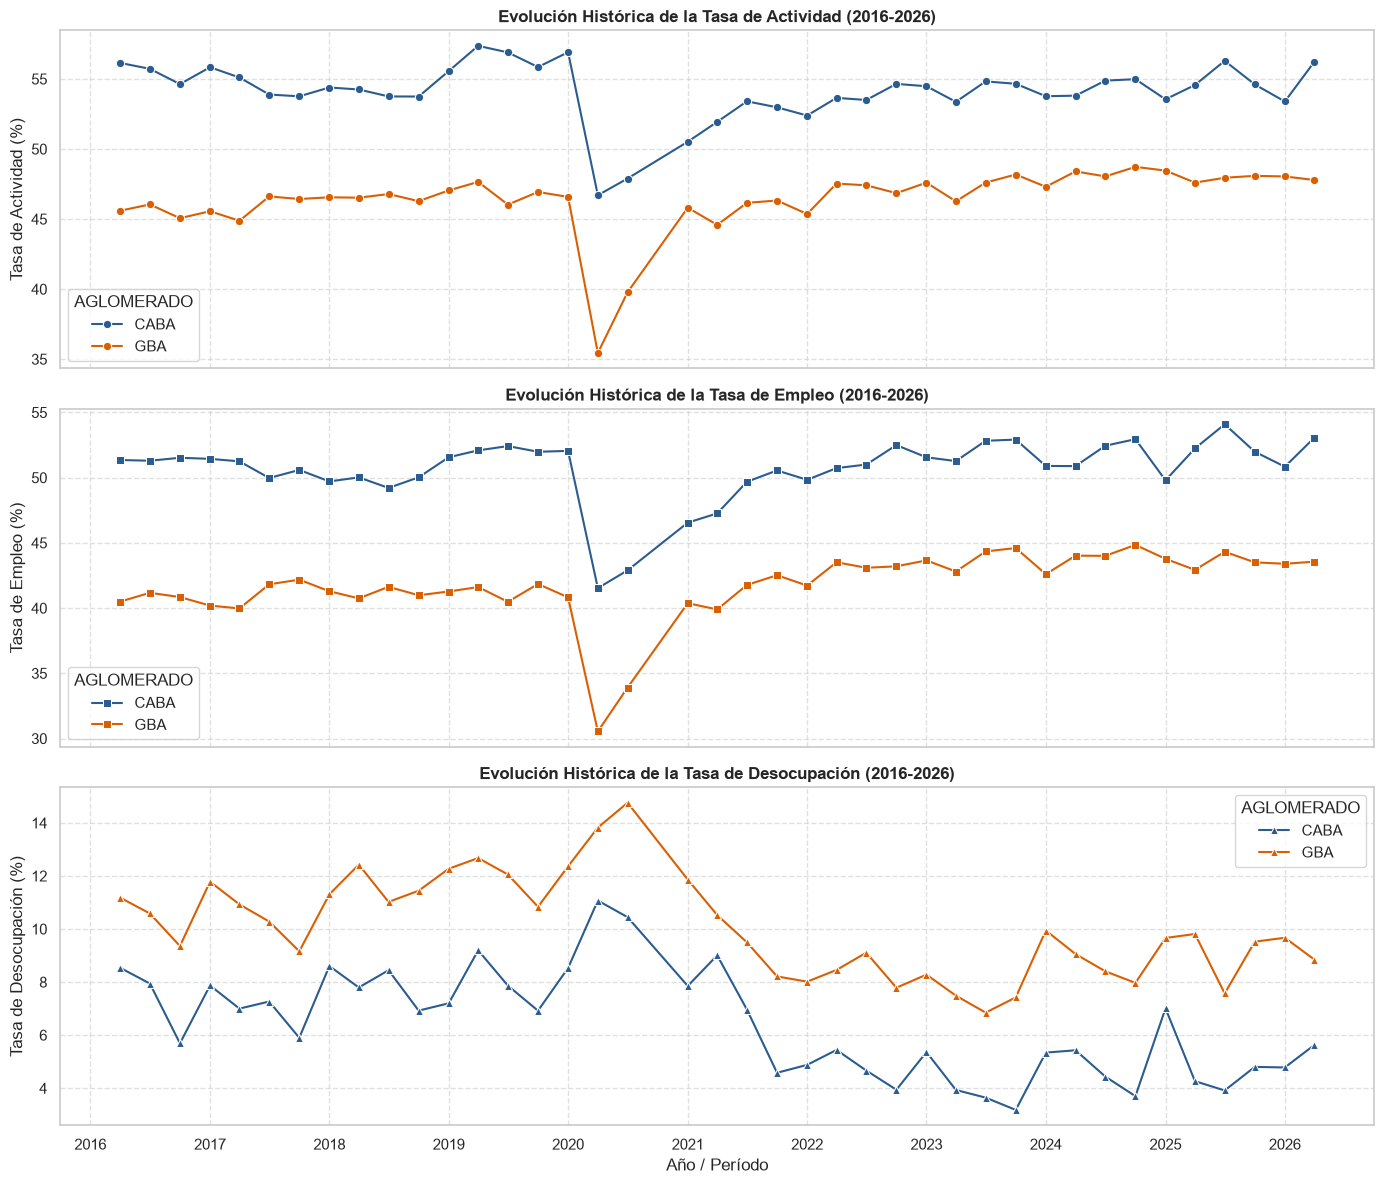

In [ ]:
# CÁLCULO DE TASAS HISTÓRICAS PONDERADAS (40 TRIMESTRES)
def calcular_tasas_trimestrales(df):
    resultados = []
    
    # Agrupamos por Año, Trimestre y Aglomerado
    for (ano, trim, aglo_txt), grupo in df.groupby(['ANO4', 'TRIMESTRE', 'AGLOMERADO_TXT']):
        pob_total = grupo['PONDERA'].sum()
        ocupados = grupo[grupo['ESTADO'] == 1]['PONDERA'].sum()
        desocupados = grupo[grupo['ESTADO'] == 2]['PONDERA'].sum()
        pea = ocupados + desocupados
        
        t_act = (pea / pob_total) * 100 if pob_total > 0 else np.nan
        t_emp = (ocupados / pob_total) * 100 if pob_total > 0 else np.nan
        t_des = (desocupados / pea) * 100 if pea > 0 else np.nan
        
        periodo_label = f"{int(ano)}-T{int(trim)}"
        # Fecha aproximada para ordenar cronológicamente
        mes_inicio = (int(trim) - 1) * 3 + 1
        fecha_dt = pd.to_datetime(f"{int(ano)}-{mes_inicio:02d}-01")
        
        resultados.append({
            'FECHA': fecha_dt,
            'PERIODO': periodo_label,
            'ANO': int(ano),
            'TRIM': int(trim),
            'AGLOMERADO': aglo_txt,
            'Poblacion': pob_total,
            'PEA': pea,
            'Ocupados': ocupados,
            'Desocupados': desocupados,
            'Tasa_Actividad': t_act,
            'Tasa_Empleo': t_emp,
            'Tasa_Desocupacion': t_des
        })
        
    df_tasas = pd.DataFrame(resultados).sort_values(['FECHA', 'AGLOMERADO'])
    return df_tasas

df_tasas_historicas = calcular_tasas_trimestrales(df_historico)
print(f"Total registros en serie de tasas: {len(df_tasas_historicas)}")
display(df_tasas_historicas.head(4))

# GRÁFICOS DE EVOLUCIÓN HISTÓRICA (TASAS DE ACTIVIDAD, EMPLEO Y DESOCUPACIÓN)
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

colores = {'CABA': '#2b5c8f', 'GBA': '#d95f02'}

# 1. Tasa de Actividad
sns.lineplot(data=df_tasas_historicas, x='FECHA', y='Tasa_Actividad', hue='AGLOMERADO', 
             palette=colores, marker='o', ax=axes[0])
axes[0].set_title('Evolución Histórica de la Tasa de Actividad (2016-2026)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Tasa de Actividad (%)')
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. Tasa de Empleo
sns.lineplot(data=df_tasas_historicas, x='FECHA', y='Tasa_Empleo', hue='AGLOMERADO', 
             palette=colores, marker='s', ax=axes[1])
axes[1].set_title('Evolución Histórica de la Tasa de Empleo (2016-2026)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Tasa de Empleo (%)')
axes[1].grid(True, linestyle='--', alpha=0.6)

# 3. Tasa de Desocupación
sns.lineplot(data=df_tasas_historicas, x='FECHA', y='Tasa_Desocupacion', hue='AGLOMERADO', 
             palette=colores, marker='^', ax=axes[2])
axes[2].set_title('Evolución Histórica de la Tasa de Desocupación (2016-2026)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Tasa de Desocupación (%)')
axes[2].set_xlabel('Año / Período')
axes[2].grid(True, linestyle='--', alpha=0.6)

# Configurar etiquetas del eje X con formato año
import matplotlib.dates as mdates
axes[2].xaxis.set_major_locator(mdates.YearLocator())
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
fig.savefig("grafico_evolucion_tasas_historicas.png", dpi=300, bbox_inches='tight')
plt.show()

--- EVOLUCIÓN HISTÓRICA DE INGRESOS REALES (A valores constantes de 2026) ---


,ANO4,TRIMESTRE,PERIODO_TXT,AGLOMERADO_TXT,Media_Real,Mediana_Real,Q1_Real,Q3_Real,P10_Real,P90_Real,FECHA
0,2016,2,2016-T2,CABA,1591032.27,1279800.00,829500.00,1896000.00,374460.00,2962500.00,2016-04-01
1,2016,2,2016-T2,GBA,1156943.75,948000.00,568800.00,1422000.00,237000.00,2133000.00,2016-04-01
2,2016,3,2016-T3,CABA,1709047.23,1405000.00,899200.00,2248000.00,449600.00,3034800.00,2016-07-01
3,2016,3,2016-T3,GBA,1150222.91,1011600.00,562000.00,1461200.00,269760.00,2248000.00,2016-07-01


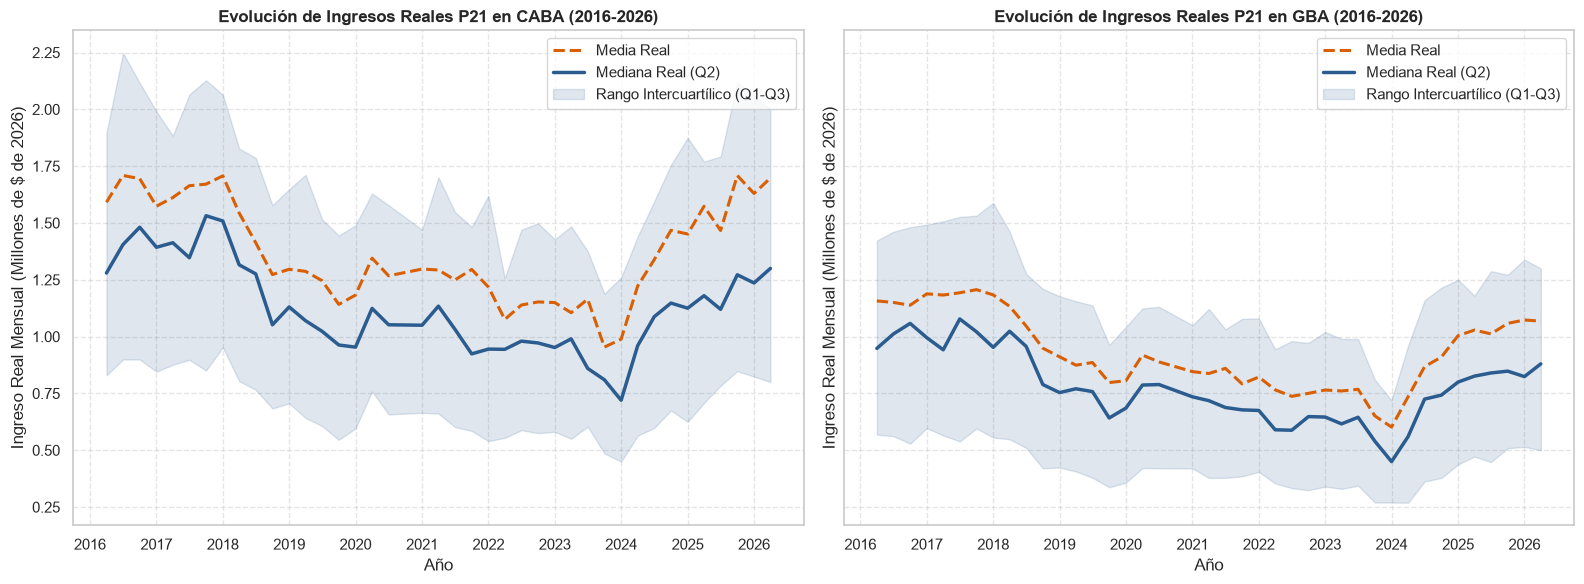

In [ ]:
# AJUSTE DE INGRESOS POR INFLACIÓN (SERIE IPC TRIMESTRAL 2016-2026)

# Serie oficial aproximada del IPC trimestral
# Factor de ajuste para multiplicar el ingreso nominal de cada trimestre y llevarlo a $ de T2 2026
factores_inflacion = {
    # 2016
    '2016-T2': 118.5, '2016-T3': 112.4, '2016-T4': 105.8,
    # 2017
    '2017-T1': 99.5, '2017-T2': 94.2, '2017-T3': 89.8, '2017-T4': 85.1,
    # 2018
    '2018-T1': 79.4, '2018-T2': 73.1, '2018-T3': 63.8, '2018-T4': 52.6,
    # 2019
    '2019-T1': 47.1, '2019-T2': 42.8, '2019-T3': 37.9, '2019-T4': 32.1,
    # 2020
    '2020-T1': 29.8, '2020-T2': 28.1, '2020-T3': 26.3, '2020-T4': 23.4,
    # 2021
    '2021-T1': 21.0, '2021-T2': 18.9, '2021-T3': 17.2, '2021-T4': 15.4,
    # 2022
    '2022-T1': 13.5, '2022-T2': 11.8, '2022-T3': 9.8,  '2022-T4': 8.1,
    # 2023
    '2023-T1': 6.8,  '2023-T2': 5.5,  '2023-T3': 4.3,  '2023-T4': 2.7,
    # 2024
    '2024-T1': 1.8,  '2024-T2': 1.6,  '2024-T3': 1.45, '2024-T4': 1.35,
    # 2025
    '2025-T1': 1.25, '2025-T2': 1.18, '2025-T3': 1.12, '2025-T4': 1.06,
    # 2026
    '2026-T1': 1.03, '2026-T2': 1.00
}

# 1. Filtrar ocupados con ingresos positivos declarados
ocupados_historico = df_historico[(df_historico['ESTADO'] == 1) & (df_historico['P21'] > 0)].copy()

# 2. Aplicar deflactor a cada registro según su período
ocupados_historico['FACTOR_IPC'] = ocupados_historico['PERIODO_TXT'].map(factores_inflacion).fillna(1.0)
ocupados_historico['P21_REAL'] = ocupados_historico['P21'] * ocupados_historico['FACTOR_IPC']

# 3. Calcular medidas de tendencia central y posición por Período y Aglomerado
def calcular_metricas_ingreso_real(grupo):
    # Usamos percentiles ponderados o métricas muestrales
    s = grupo['P21_REAL']
    return pd.Series({
        'Media_Real': s.mean(),
        'Mediana_Real': s.median(),
        'Q1_Real': s.quantile(0.25),
        'Q3_Real': s.quantile(0.75),
        'P10_Real': s.quantile(0.10),
        'P90_Real': s.quantile(0.90)
    })

df_ingresos_historicos = ocupados_historico.groupby(
    ['ANO4', 'TRIMESTRE', 'PERIODO_TXT', 'AGLOMERADO_TXT']
).apply(calcular_metricas_ingreso_real, include_groups=False).reset_index()

# Ordenar por fecha cronológica
df_ingresos_historicos['FECHA'] = pd.to_datetime(
    df_ingresos_historicos['ANO4'].astype(int).astype(str) + '-' + 
    ((df_ingresos_historicos['TRIMESTRE'].astype(int) - 1) * 3 + 1).astype(str).str.zfill(2) + '-01'
)
df_ingresos_historicos = df_ingresos_historicos.sort_values(['FECHA', 'AGLOMERADO_TXT'])

print("--- EVOLUCIÓN HISTÓRICA DE INGRESOS REALES (A valores constantes de 2026) ---")
display(df_ingresos_historicos.head(4))

# GRÁFICO: EVOLUCIÓN DE TENDENCIA CENTRAL Y POSICIÓN
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for i, aglo in enumerate(['CABA', 'GBA']):
    sub = df_ingresos_historicos[df_ingresos_historicos['AGLOMERADO_TXT'] == aglo]
    
    # Línea de Media y Mediana (Tendencia Central)
    axes[i].plot(sub['FECHA'], sub['Media_Real'] / 1e6, label='Media Real', color='#d95f02', linewidth=2.2, linestyle='--')
    axes[i].plot(sub['FECHA'], sub['Mediana_Real'] / 1e6, label='Mediana Real (Q2)', color='#2b5c8f', linewidth=2.5)
    
    # Área sombreada entre Q1 y Q3 (Medidas de Posición / Dispersión intercuartílica)
    axes[i].fill_between(sub['FECHA'], sub['Q1_Real'] / 1e6, sub['Q3_Real'] / 1e6, 
                         color='#2b5c8f', alpha=0.15, label='Rango Intercuartílico (Q1-Q3)')
    
    axes[i].set_title(f'Evolución de Ingresos Reales P21 en {aglo} (2016-2026)', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Ingreso Real Mensual (Millones de $ de 2026)')
    axes[i].set_xlabel('Año')
    axes[i].legend(loc='upper right')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
fig.savefig("grafico_evolucion_ingresos_reales.png", dpi=300, bbox_inches='tight')
plt.show()

--- BRECHA SALARIAL DE GÉNERO (Mediana Real) ---


SEXO_TXT                 Mujer      Varón  Brecha (%)
ANO4 AGLOMERADO_TXT                                  
2016 CABA           1185000.00 1573600.00       24.70
     GBA             775715.00 1124000.00       31.00
2017 CABA           1276500.00 1507200.00       15.30
     GBA             796000.00 1191400.00       33.20
2018 CABA           1148400.00 1388900.00       17.30
     GBA             714600.00 1084600.00       34.10
2019 CABA            942000.00 1137000.00       17.20
     GBA             568500.00  856000.00       33.60
2020 CABA            920500.00 1183500.00       22.20
     GBA             596000.00  789000.00       24.50
2021 CABA            924000.00 1118000.00       17.40
     GBA             546000.00  812700.00       32.80
2022 CABA            810000.00 1014800.00       20.20
     GBA             486000.00  729000.00       33.30
2023 CABA            810000.00  989000.00       18.10
     GBA             462400.00  688000.00       32.80
2024 CABA            878750.00 1080000.00       18.60
     GBA             480000.00  720000.00       33.30
2025 CABA           1038800.00 1250000.00       16.90
     GBA             636000.00 1000000.00       36.40
2026 CABA           1106220.00 1500000.00       26.30
     GBA             700000.00 1030000.00       32.00


--- INGRESO MEDIANO REAL POR NIVEL EDUCATIVO (2016 vs 2026) ---


NIVEL_ED_TXT                Hasta Primaria Inc.  Secundaria Completa  \
PERIODO_TXT AGLOMERADO_TXT                                             
2016-T2     CABA                      948000.00           1185000.00   
            GBA                       675450.00           1007250.00   
2026-T2     CABA                      110000.00           1200000.00   
            GBA                       470000.00            900000.00   

NIVEL_ED_TXT                Superior Completo  
PERIODO_TXT AGLOMERADO_TXT                     
2016-T2     CABA                   1777500.00  
            GBA                    1659000.00  
2026-T2     CABA                   1700000.00  
            GBA                    1200000.00

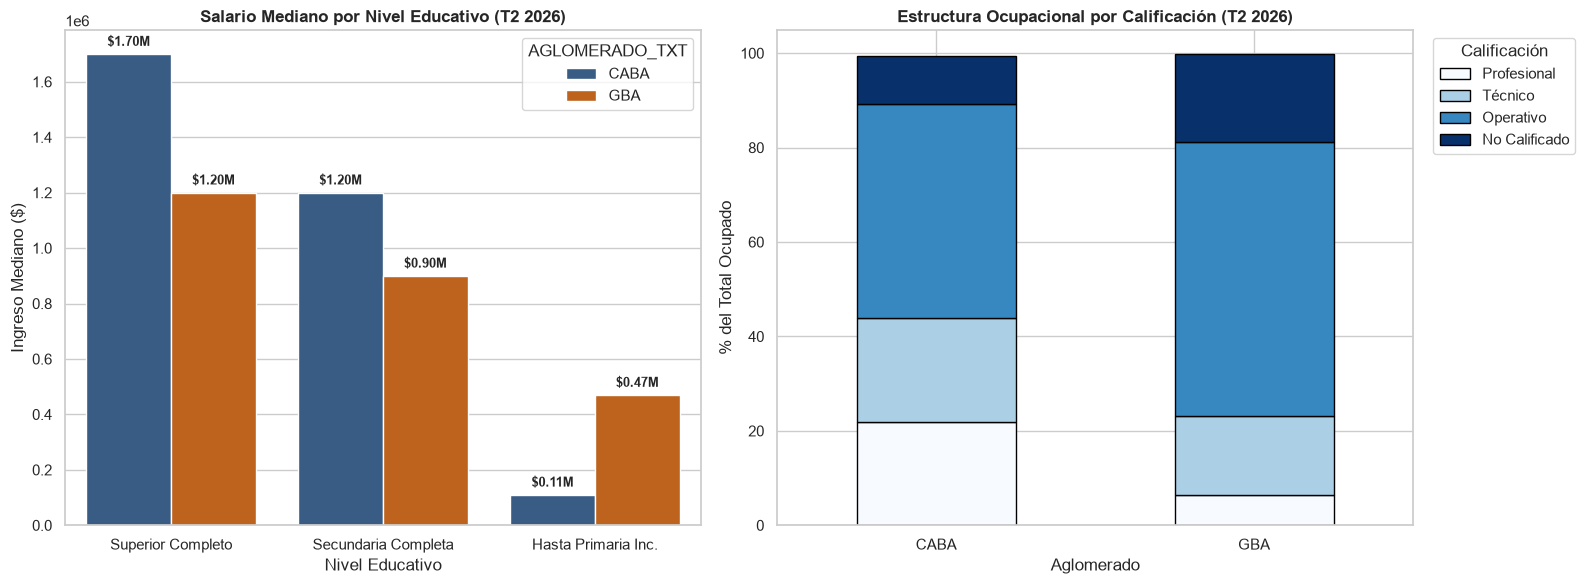

In [ ]:
# ANÁLISIS MULTIVARIADO: EMPLEO, CALIFICACIÓN, EDUCACIÓN Y GÉNERO

# Clasificadores sobre df_historico
def mapear_calificacion(cod):
    try:
        cod_str = str(int(float(cod))).zfill(5)
        jerarquia = cod_str[-1]
        mapping = {'1': 'Profesional', '2': 'Técnico', '3': 'Operativo', '4': 'No Calificado'}
        return mapping.get(jerarquia, 'Otro')
    except:
        return 'Sin Dato'

def mapear_rama(cod):
    try:
        c = int(float(str(int(float(cod)))[:2]))
        if c <= 3: return 'Agro'
        elif 10 <= c <= 33: return 'Industria'
        elif 41 <= c <= 43: return 'Construcción'
        elif 45 <= c <= 47: return 'Comercio'
        elif 49 <= c <= 53: return 'Transporte'
        elif 58 <= c <= 66: return 'Finanzas e Informática'
        elif 84 <= c <= 88: return 'Adm. Pública, Salud y Educ.'
        elif 97 <= c <= 98: return 'Servicio Doméstico'
        else: return 'Otros Servicios'
    except:
        return 'Otros Servicios'

def clasificar_educacion(val):
    if val in [7, 1]: return 'Hasta Primaria Inc.'
    elif val == 2: return 'Primaria Completa'
    elif val == 3: return 'Secundaria Inc.'
    elif val == 4: return 'Secundaria Completa'
    elif val == 5: return 'Superior Inc.'
    elif val == 6: return 'Superior Completo'
    else: return 'Sin Dato'

# Aplicamos a los ocupados históricos
ocupados_multi = ocupados_historico.copy()
ocupados_multi['CALIFICACION'] = ocupados_multi['PP04D_COD'].apply(mapear_calificacion)
ocupados_multi['RAMA'] = ocupados_multi['PP04B_COD'].apply(mapear_rama)
ocupados_multi['NIVEL_ED_TXT'] = ocupados_multi['NIVEL_ED'].apply(clasificar_educacion)
ocupados_multi['SEXO_TXT'] = ocupados_multi['CH04'].map({1: 'Varón', 2: 'Mujer'})

# BRECHA DE GÉNERO EN INGRESOS REALES (Evolución por Aglomerado)
brecha_genero = ocupados_multi.groupby(['ANO4', 'AGLOMERADO_TXT', 'SEXO_TXT'])['P21_REAL'].median().unstack()
brecha_genero['Brecha (%)'] = ((brecha_genero['Varón'] - brecha_genero['Mujer']) / brecha_genero['Varón']) * 100

print("--- BRECHA SALARIAL DE GÉNERO (Mediana Real) ---")
display(brecha_genero.round(1))

# INGRESOS REALES SEGÚN NIVEL EDUCATIVO (Último período T2 2026 vs Base 2016)
ingreso_educ = ocupados_multi[ocupados_multi['PERIODO_TXT'].isin(['2016-T2', '2026-T2'])].groupby(
    ['PERIODO_TXT', 'AGLOMERADO_TXT', 'NIVEL_ED_TXT']
)['P21_REAL'].median().unstack().round(0)

print("\n--- INGRESO MEDIANO REAL POR NIVEL EDUCATIVO (2016 vs 2026) ---")
display(ingreso_educ[['Hasta Primaria Inc.', 'Secundaria Completa', 'Superior Completo']])

# GRÁFICOS MULTIVARIADOS
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico A: Ingresos Reales por Nivel Educativo en 2026
datos_educ_2026 = ocupados_multi[ocupados_multi['PERIODO_TXT'] == '2026-T2']
sns.barplot(
    data=datos_educ_2026[datos_educ_2026['NIVEL_ED_TXT'].isin(['Hasta Primaria Inc.', 'Secundaria Completa', 'Superior Completo'])],
    x='NIVEL_ED_TXT',
    y='P21_REAL',
    hue='AGLOMERADO_TXT',
    estimator=np.median,
    errorbar=None,
    palette={'CABA': '#2b5c8f', 'GBA': '#d95f02'},
    ax=axes[0]
)
axes[0].set_title('Salario Mediano por Nivel Educativo (T2 2026)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Ingreso Mediano ($)')
axes[0].set_xlabel('Nivel Educativo')
for p in axes[0].patches:
    h = p.get_height()
    if h > 0:
        axes[0].annotate(f"${h/1e6:.2f}M", (p.get_x() + p.get_width() / 2., h + 20000),
                         ha='center', va='bottom', fontsize=9, fontweight='bold')

# Gráfico B: Distribución de Calificación Ocupacional (PP04D_COD)
datos_calif = ocupados_multi[ocupados_multi['PERIODO_TXT'] == '2026-T2']
calif_counts = pd.crosstab(datos_calif['AGLOMERADO_TXT'], datos_calif['CALIFICACION'], normalize='index') * 100
calif_counts[['Profesional', 'Técnico', 'Operativo', 'No Calificado']].plot(
    kind='bar', 
    stacked=True, 
    colormap='Blues', 
    edgecolor='black',
    ax=axes[1]
)
axes[1].set_title('Estructura Ocupacional por Calificación (T2 2026)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('% del Total Ocupado')
axes[1].set_xlabel('Aglomerado')
axes[1].legend(title='Calificación', bbox_to_anchor=(1.02, 1), loc='upper left')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
fig.savefig("graficos_multivariado_educacion_calificacion.png", dpi=300, bbox_inches='tight')
plt.show()